# YOLOv8-S Model Evaluation

Evaluation of the trained YOLOv8-S object detection model on the RDD2022 test dataset.

### Evaluation includes
- Overall detection metrics
- Per-class detection metrics
- AP@0.5 for each class
- mAP@0.5
- mAP@0.5:0.95
- Ground-truth vs prediction visualizations

## 1. Setup

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
!pip install -q git+https://github.com/gracyy-rm/cv-toolkit.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import cvcore 
from cvcore.metric_operations.detection import DatasetEvaluator, ImageEvaluator

## Paths 

In [5]:
GT_DIR = Path("/kaggle/input/datasets/gracyyadav79/annotations-pred/test_jsons/gt/test")
PRED_DIR = Path("/kaggle/input/datasets/gracyyadav79/yolos-pred/yolo")

OUTPUT_DIR = Path("/kaggle/working/yolov8s_evaluation")
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

## Verify Evaluation files

In [6]:
gt_files = sorted(GT_DIR.glob("*.json"))
pred_files = sorted(PRED_DIR.glob("*json"))

print(f"Ground-truth files :  {len(gt_files)}")
print(f"Predictions files : {len(pred_files)}")

Ground-truth files :  5758
Predictions files : 5758


In [7]:
gt_ids = {path.stem for path in gt_files}
pred_ids = {path.stem for path in pred_files}

print(f"GT files without predictions : {len(gt_ids - pred_ids)}")
print(f"Predictions without GT        : {len(pred_ids - gt_ids)}")
print(f"Matched image files           : {len(gt_ids & pred_ids)}")

GT files without predictions : 0
Predictions without GT        : 0
Matched image files           : 5758


##  Single-Image Evaluation

`ImageEvaluator` is used to inspect the detection performance of an individual image.

The evaluation includes:

- Ground-truth annotations
- Model predictions
- IoU-based matching
- TP, FP and FN
- Precision, Recall and F1-score
- Mean IoU
- Per-class detection metrics

In [9]:
image_id = gt_files[0].stem

image_evaluator = ImageEvaluator(
    gt_path_or_data=GT_DIR / f"{image_id}.json",
    pred_path_or_data=PRED_DIR / f"{image_id}.json",
    threshold = 0.5
)

print(f"Image ID: {image_id}")

Image ID: China_Drone_000008


In [10]:
image_evaluator.get_stat(
    confidence_thresholds=[0.1, 0.2, 0.3, 0.4,0.5,0.6,0.7,0.8,0.9],
    threshold=0.5,
    metric_type="ios",
    return_stat=True
)


SINGLE-IMAGE OVERALL DETECTION METRICS (IOS@0.5)

+--------------+------+---------------+------+------+------+-------------+----------+------+------------+
|   Confidence |   GT |   Predictions |   TP |   FP |   FN |   Precision |   Recall |   F1 |   Mean IOS |
+==============+======+===============+======+======+======+=============+==========+======+============+
|          0.1 |    1 |             1 |    1 |    0 |    0 |           1 |        1 |    1 |     0.9305 |
+--------------+------+---------------+------+------+------+-------------+----------+------+------------+
|          0.2 |    1 |             1 |    1 |    0 |    0 |           1 |        1 |    1 |     0.9305 |
+--------------+------+---------------+------+------+------+-------------+----------+------+------------+
|          0.3 |    1 |             1 |    1 |    0 |    0 |           1 |        1 |    1 |     0.9305 |
+--------------+------+---------------+------+------+------+-------------+----------+------+---------

## checking instance of the single image

In [11]:
# 1. Verify Ground Truth and Prediction JSON data are loaded
print("GT Data loaded:", bool(image_evaluator.gt_data))
print("GT Annotations count:", len(image_evaluator.gt_data.get("annotations", [])))
print("Predictions count:", len(image_evaluator.pred_data.get("predictions", [])))

# 2. Verify Class Label Mapping is built
print("Label Mapping:", image_evaluator.label_mapping)

# 3. Verify Evaluation Results are stored (after calling get_stat)
image_evaluator.get_stat(return_stat=False)

if image_evaluator.results is not None:
    print("Evaluation results are stored in memory!")
    print("Overall metrics :", image_evaluator.results["overall"])
    print("Per-class metrics :", image_evaluator.results["per_class"])
else:
    print("Results are empty!")

GT Data loaded: True
GT Annotations count: 1
Predictions count: 1
Label Mapping: {1: 'transverse crack'}
Evaluation results are stored in memory!
Overall metrics : [{'gt_count': 1, 'prediction_count': 1, 'tp': 1, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0, 'mean_score': 0.9304935973597362, 'metric_type': 'IOS', 'confidence_threshold': 0.25, 'matched_scores': [0.9304935973597362]}, {'gt_count': 1, 'prediction_count': 1, 'tp': 1, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0, 'mean_score': 0.9304935973597362, 'metric_type': 'IOS', 'confidence_threshold': 0.5, 'matched_scores': [0.9304935973597362]}, {'gt_count': 1, 'prediction_count': 0, 'tp': 0, 'fp': 0, 'fn': 1, 'precision': 0.0, 'recall': 0.0, 'f1_score': 0.0, 'mean_score': 0.0, 'metric_type': 'IOS', 'confidence_threshold': 0.75, 'matched_scores': []}]
Per-class metrics : [{'gt_count': 1, 'prediction_count': 1, 'tp': 1, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0, 'me

## Ground Truth vs Predictions


--- Metrics for image:  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       1 |    1 |    0 |    0 |           1 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


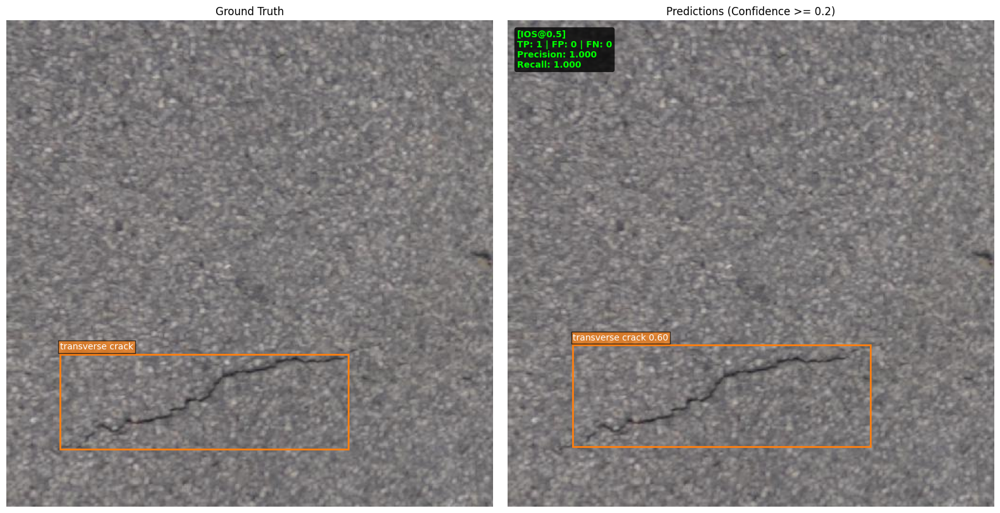

In [12]:
image_evaluator.plot(show=True,show_stats=True,confidence_threshold = 0.2)

## Additional Samples


Image: China_MotorBike_000160

--- Metrics for image:  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    3 |       4 |    3 |    1 |    0 |        0.75 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


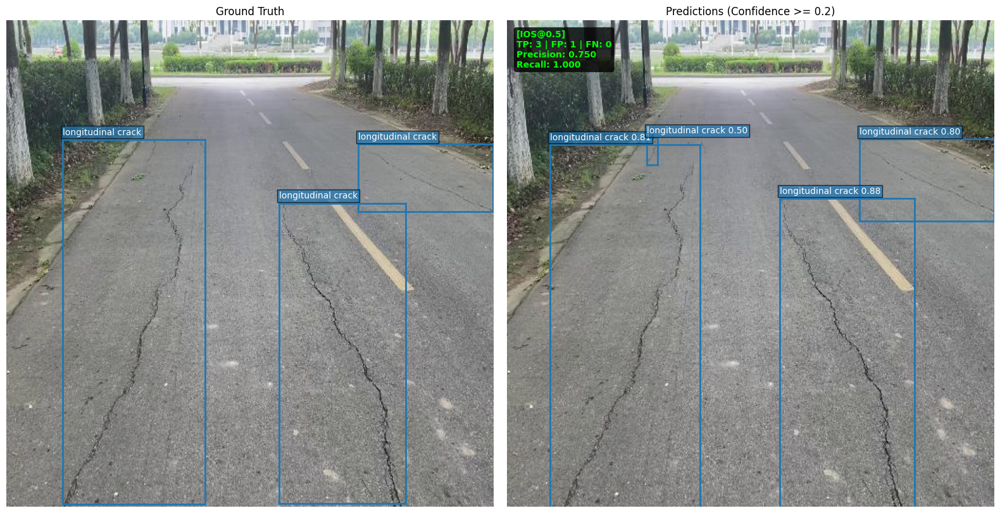


Image: Japan_007360

--- Metrics for image:  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    3 |       4 |    3 |    1 |    0 |        0.75 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


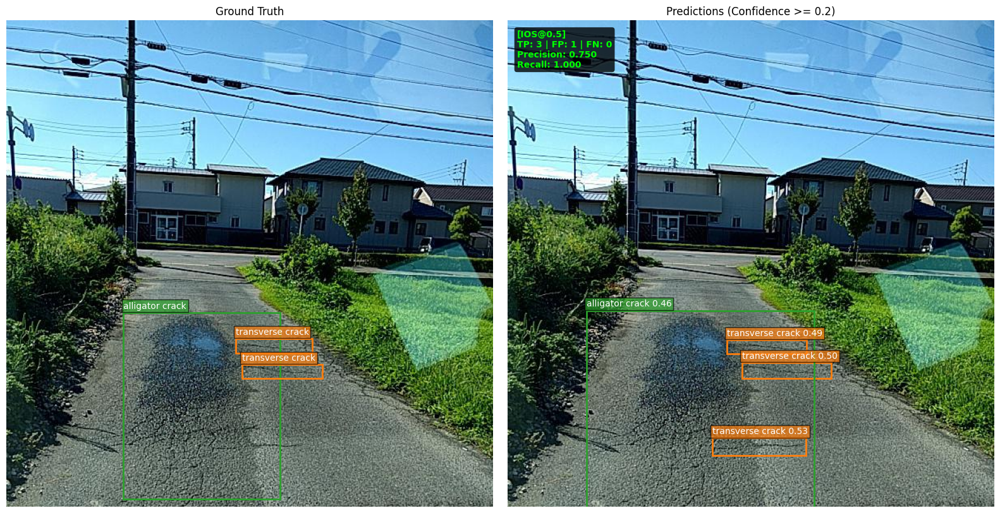


Image: Norway_006172

--- Metrics for image:  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


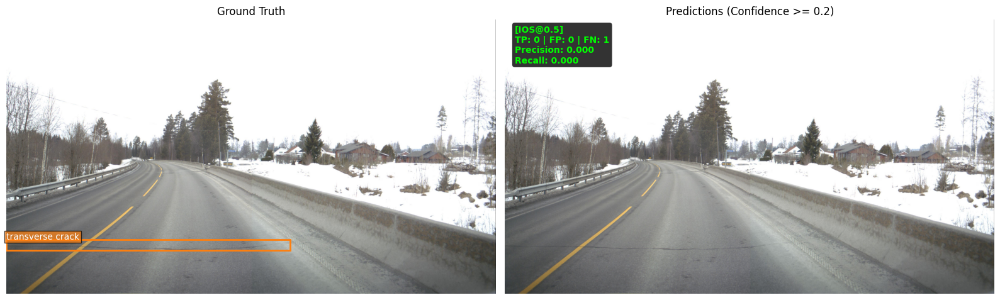

In [13]:
sample_image_ids = pd.Series(list(gt_ids & pred_ids)).sample(n=min(3, len(gt_ids & pred_ids)),random_state=42
).tolist()

for image_id in sample_image_ids:
    print(f"\nImage: {image_id}")

    evaluator = ImageEvaluator(
        gt_path_or_data=GT_DIR / f"{image_id}.json",
        pred_path_or_data=PRED_DIR / f"{image_id}.json",
        threshold=0.5,
        metric_type="ios"
    )

    evaluator.plot(
        confidence_threshold=0.2,
        show=True,
        show_stats = True
    )

## Dataset Level Evaluation

In [14]:
dataset_evaluator = DatasetEvaluator(
    gt_dir=GT_DIR,
    pred_dir=PRED_DIR,
    metric_type="ios",
)

In [15]:
dataset_evaluator.get_stat(
    confidence_thresholds=[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9],
    return_stat=True,
    metric_type = "ios",
    threshold=0.5
    
)

Evaluating (IOS): 100%|██████████| 5758/5758 [02:04<00:00, 46.20img/s]



DATASET-LEVEL OVERALL METRICS (IOS@0.5)

+--------------+------+---------------+------+------+------+-------------+----------+--------+------------+
|   Confidence |   GT |   Predictions |   TP |   FP |   FN |   Precision |   Recall |     F1 |   Mean IOS |
+==============+======+===============+======+======+======+=============+==========+========+============+
|          0.1 | 9675 |         13752 | 7713 | 6039 | 1962 |      0.5609 |   0.7972 | 0.6585 |     0.9439 |
+--------------+------+---------------+------+------+------+-------------+----------+--------+------------+
|          0.2 | 9675 |          9646 | 6768 | 2878 | 2907 |      0.7016 |   0.6995 | 0.7006 |     0.9491 |
+--------------+------+---------------+------+------+------+-------------+----------+--------+------------+
|          0.3 | 9675 |          7511 | 5917 | 1594 | 3758 |      0.7878 |   0.6116 | 0.6886 |     0.9531 |
+--------------+------+---------------+------+------+------+-------------+----------+--------+

## Checking the dataset evalautor instance 

In [16]:
print("total dataset images", len(dataset_evaluator.all_image_object))

total dataset images 5758


In [17]:
print("dataset metrics",dataset_evaluator.results)
print("overall resutls", dataset_evaluator.overall_df)
print("per_class_table",dataset_evaluator.per_class_df)
print("AP score",dataset_evaluator.ap_df)
print("MAP_50 score",dataset_evaluator.results["map_50"])
print("MAP_50:95 score",dataset_evaluator.results["map_50_95"])

dataset metrics {'overall': [{'gt_count': 9675, 'prediction_count': 13752, 'tp': 7713, 'fp': 6039, 'fn': 1962, 'precision': 0.5608638743455497, 'recall': 0.7972093023255814, 'f1_score': 0.6584709950057626, 'mean_score': 0.943938599915923, 'metric_type': 'IOS', 'confidence_threshold': 0.1}, {'gt_count': 9675, 'prediction_count': 9646, 'tp': 6768, 'fp': 2878, 'fn': 2907, 'precision': 0.7016379846568526, 'recall': 0.6995348837209302, 'f1_score': 0.700584855856322, 'mean_score': 0.9490887694864079, 'metric_type': 'IOS', 'confidence_threshold': 0.2}, {'gt_count': 9675, 'prediction_count': 7511, 'tp': 5917, 'fp': 1594, 'fn': 3758, 'precision': 0.7877779257089602, 'recall': 0.6115762273901809, 'f1_score': 0.6885837309437914, 'mean_score': 0.9531334162061358, 'metric_type': 'IOS', 'confidence_threshold': 0.3}, {'gt_count': 9675, 'prediction_count': 5920, 'tp': 5040, 'fp': 880, 'fn': 4635, 'precision': 0.8513513513513513, 'recall': 0.5209302325581395, 'f1_score': 0.6463610131452389, 'mean_score

In [18]:
sample_image = dataset_evaluator.all_image_object["China_Drone_000017"]
print(sample_image.results)

{'overall': [{'gt_count': 1, 'prediction_count': 1, 'tp': 1, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0, 'mean_score': 0.8485727272727266, 'metric_type': 'IOS', 'confidence_threshold': 0.1, 'matched_scores': [0.8485727272727266]}, {'gt_count': 1, 'prediction_count': 1, 'tp': 1, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0, 'mean_score': 0.8485727272727266, 'metric_type': 'IOS', 'confidence_threshold': 0.2, 'matched_scores': [0.8485727272727266]}, {'gt_count': 1, 'prediction_count': 1, 'tp': 1, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0, 'mean_score': 0.8485727272727266, 'metric_type': 'IOS', 'confidence_threshold': 0.3, 'matched_scores': [0.8485727272727266]}, {'gt_count': 1, 'prediction_count': 1, 'tp': 1, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0, 'mean_score': 0.8485727272727266, 'metric_type': 'IOS', 'confidence_threshold': 0.4, 'matched_scores': [0.8485727272727266]}, {'gt_count': 1, 'pr

In [19]:
dataset_metric_dir = Path("/kaggle/working/Yolov8L_evaluation")
dataset_metric_dir.mkdir(parents=True, exist_ok=True)

In [20]:
dataset_evaluator.overall_df.to_csv(dataset_metric_dir/"overall")

In [21]:
dataset_evaluator.per_class_df.to_csv(dataset_metric_dir/"per_class")

In [22]:
dataset_evaluator.ap_df.to_csv(dataset_metric_dir/"ap_df")

In [34]:
import shutil

folder_path = "/kaggle/working/yolov8s_evaluation"
output_path = "/kaggle/working/yolov8s_evaluation"

shutil.make_archive(output_path, "zip", folder_path)


'/kaggle/working/yolov8s_evaluation.zip'

## Conditional filtering to evaluate

Filter matched 284 / 5758 images.

--- Metrics for image: [Czech_003241]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       1 |    0 |    1 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


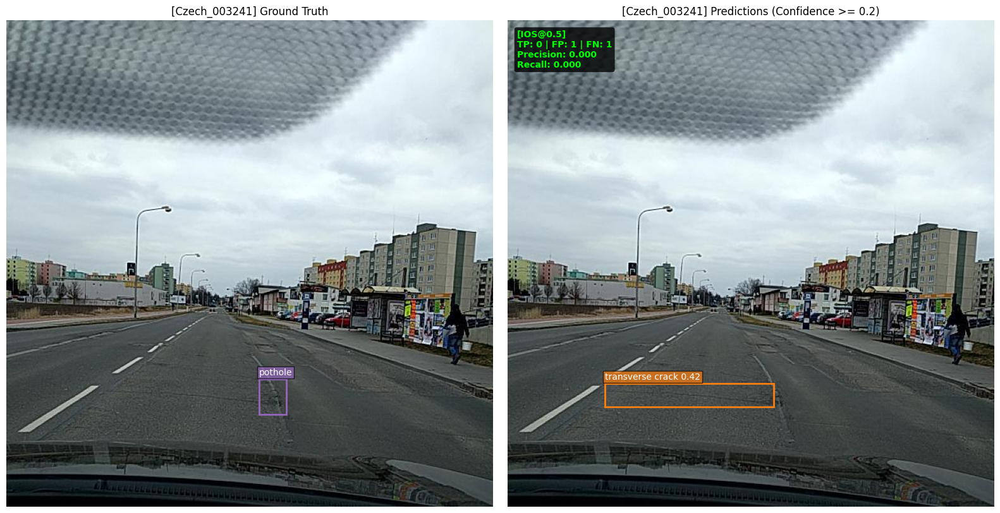


--- Metrics for image: [Japan_001641]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       1 |    0 |    1 |    2 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


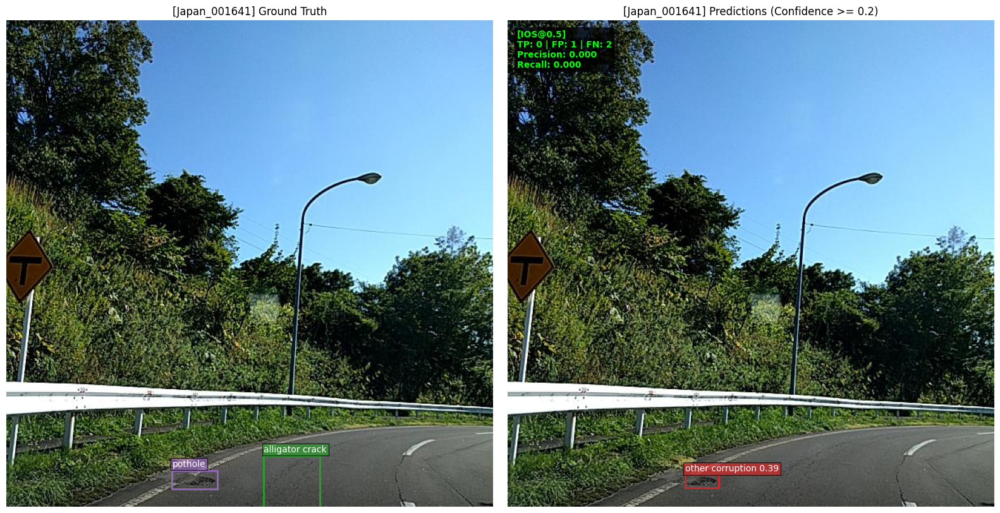


--- Metrics for image: [Japan_011944]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       2 |    1 |    1 |    1 |         0.5 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


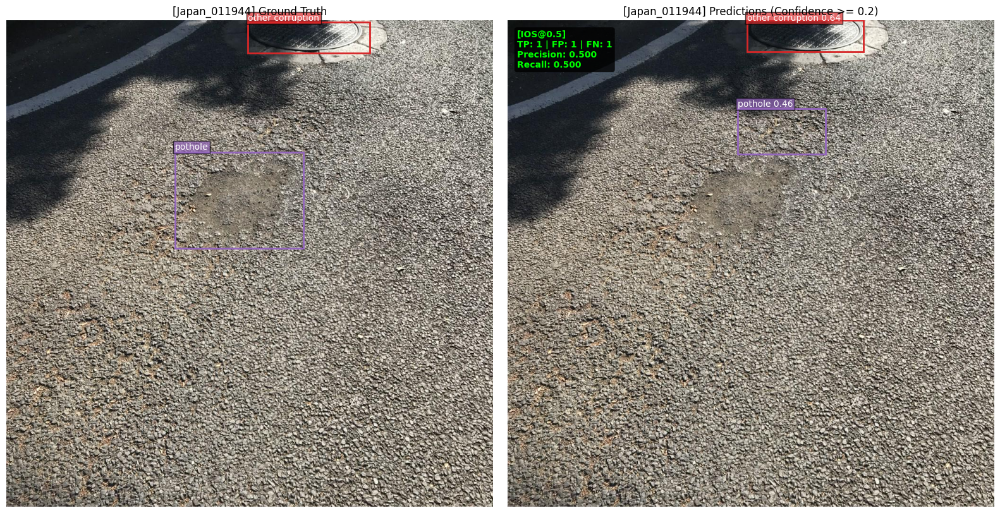


--- Metrics for image: [Norway_005693]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       0 |    0 |    0 |    2 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


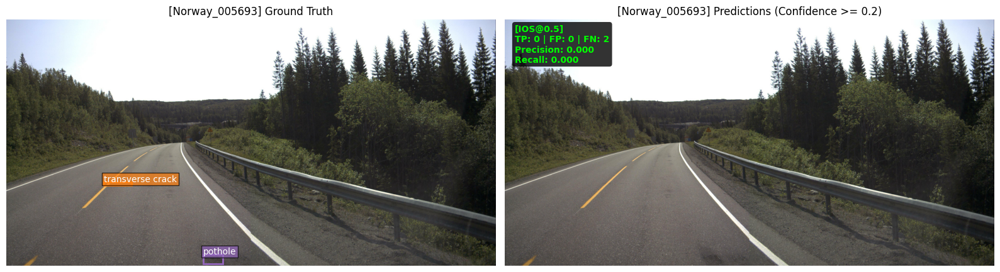


--- Metrics for image: [India_006933]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    3 |       1 |    1 |    0 |    2 |           1 |   0.3333 |
+------------------+------+---------+------+------+------+-------------+----------+


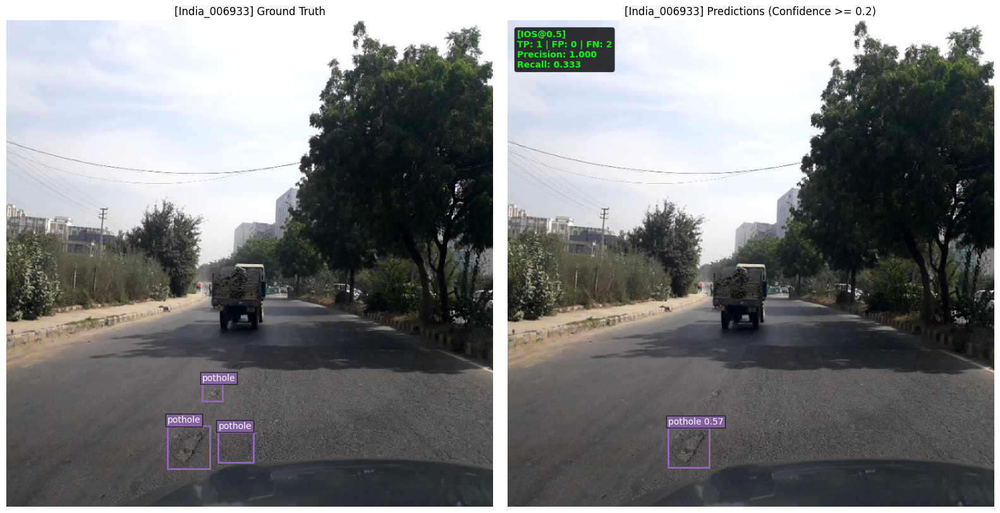

In [24]:
# pothole : recall == 0.0 
potholes_fn = dataset_evaluator.filter(
    class_names=["pothole"],
    model_confidence_threshold=0.2,
    metric="fn",
    eq=">",
    class_confidence_threshold=0
)
potholes_fn.plot(
    num_samples=5,
    confidence_threshold = 0.2,
    random_sample=True,
    model_confidence_threshold=0.2,
    show=True,
    show_stats=True
    )

Filter matched 194 / 5758 images.

--- Metrics for image: [India_009679] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       2 |    0 |    2 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


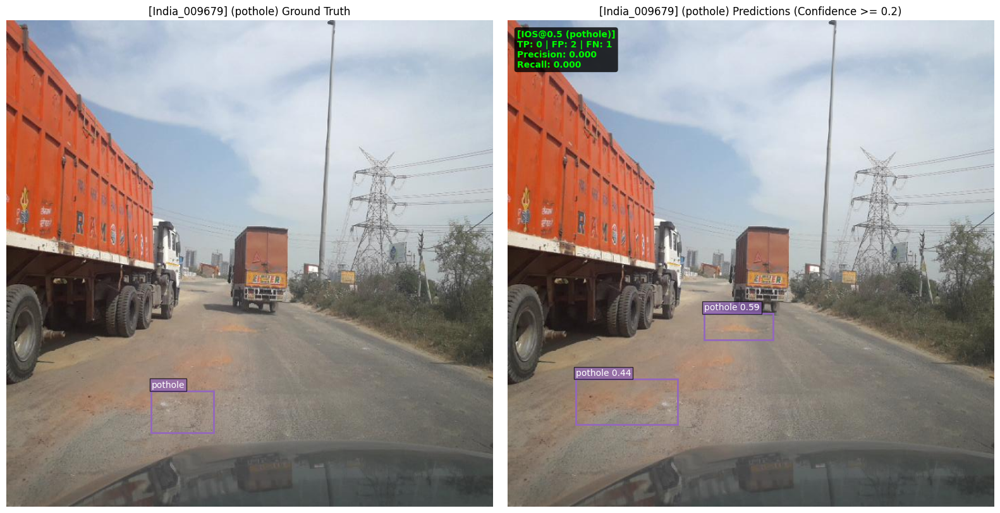


--- Metrics for image: [Czech_002501] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


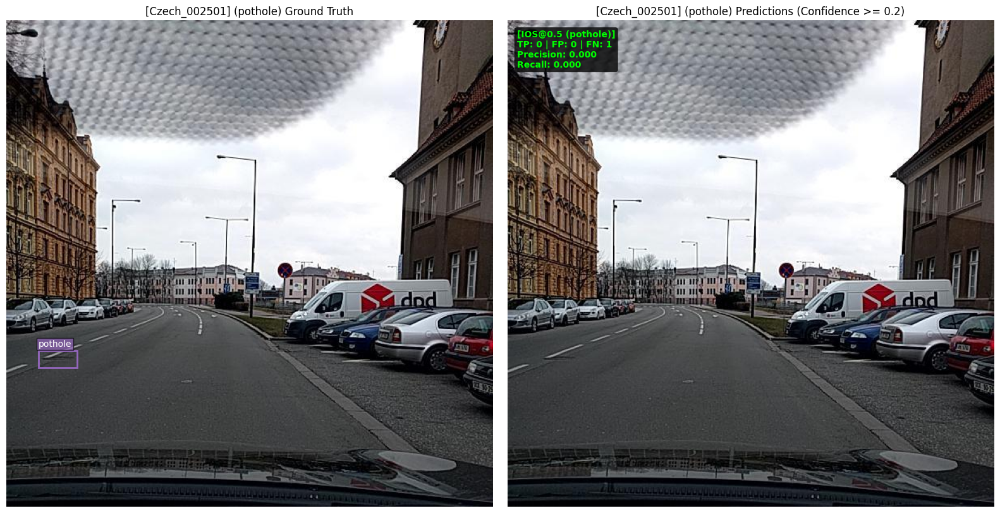


--- Metrics for image: [Czech_000839] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


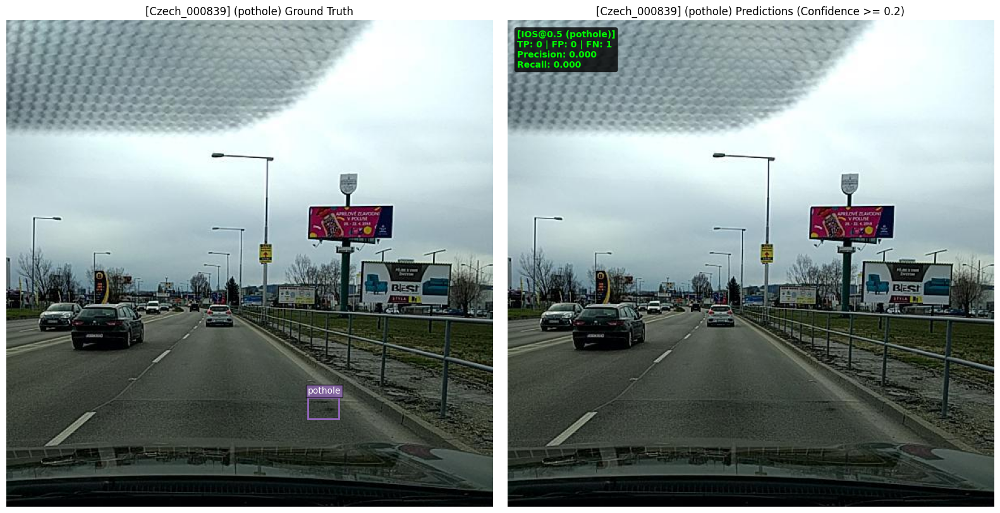


--- Metrics for image: [Japan_001441] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    3 |       0 |    0 |    0 |    3 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


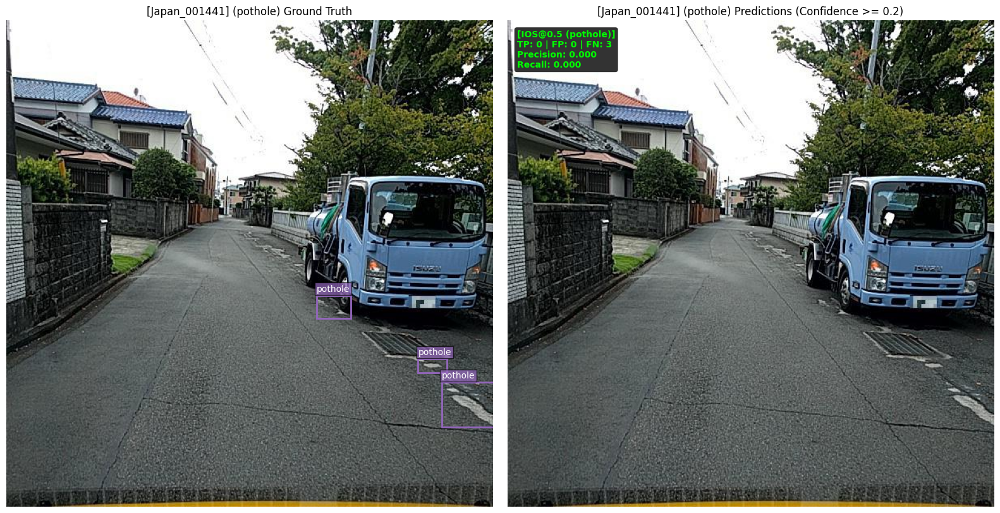


--- Metrics for image: [Norway_000720] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       0 |    0 |    0 |    2 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


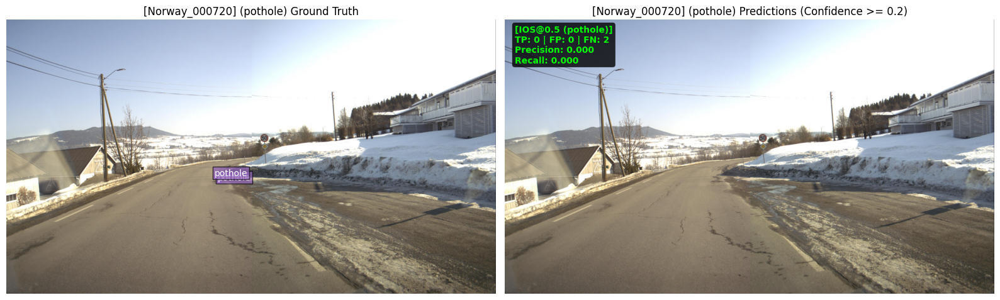


--- Metrics for image: [United_States_001540] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


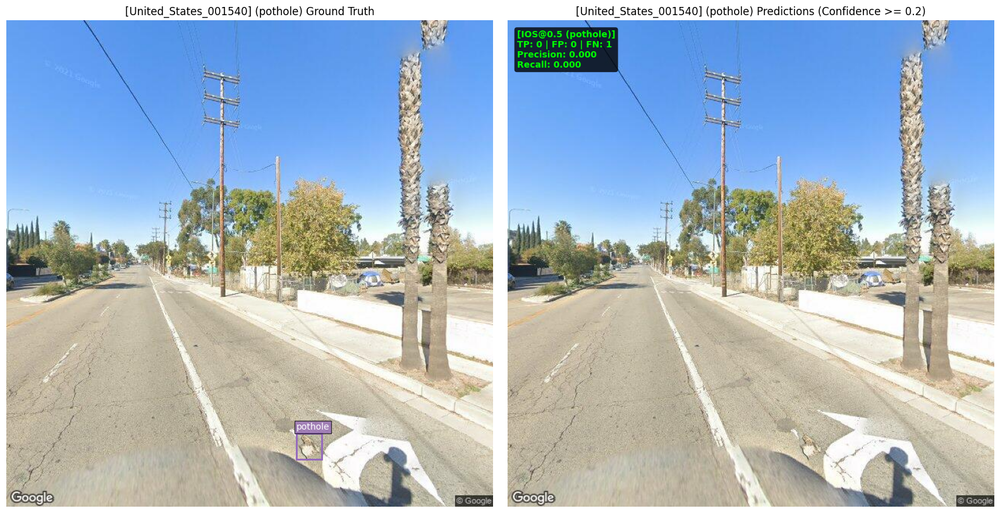


--- Metrics for image: [Japan_003881] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    6 |       0 |    0 |    0 |    6 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


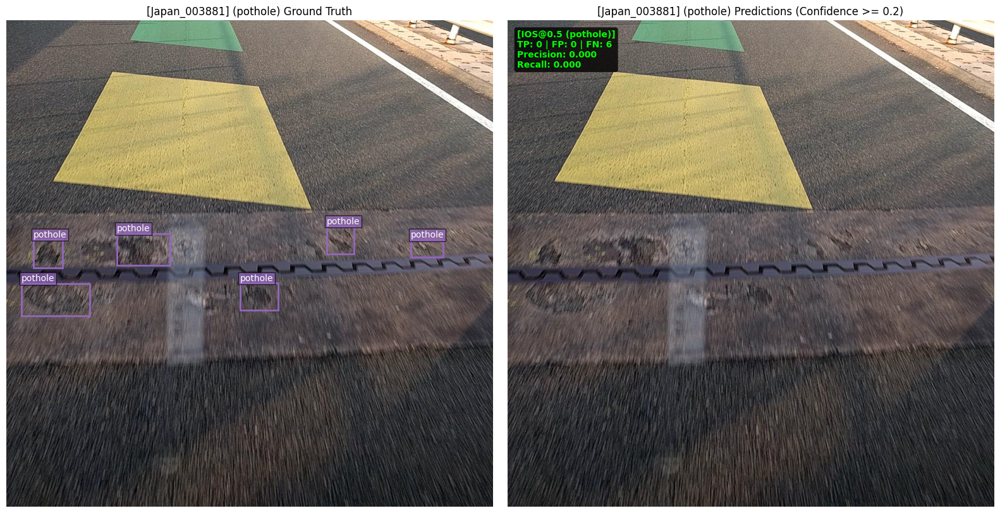


--- Metrics for image: [India_002248] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    3 |       1 |    1 |    0 |    2 |           1 |   0.3333 |
+------------------+------+---------+------+------+------+-------------+----------+


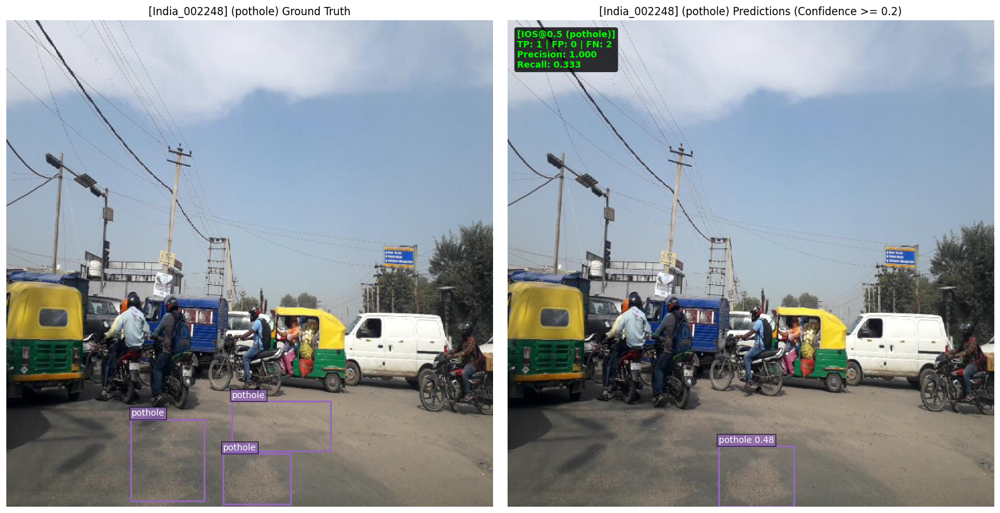


--- Metrics for image: [Norway_006526] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


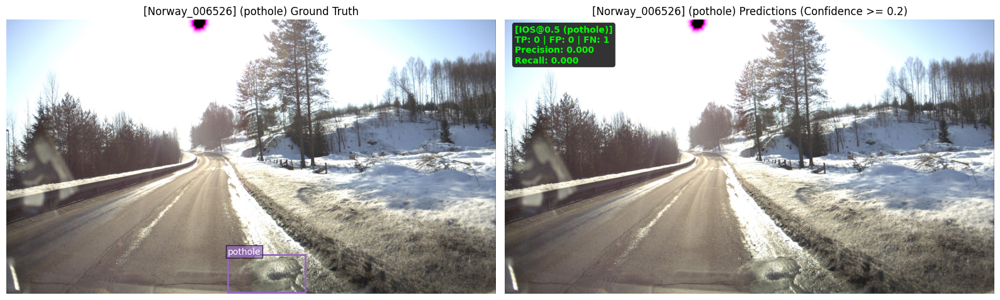


--- Metrics for image: [India_006920] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    3 |       0 |    0 |    0 |    3 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


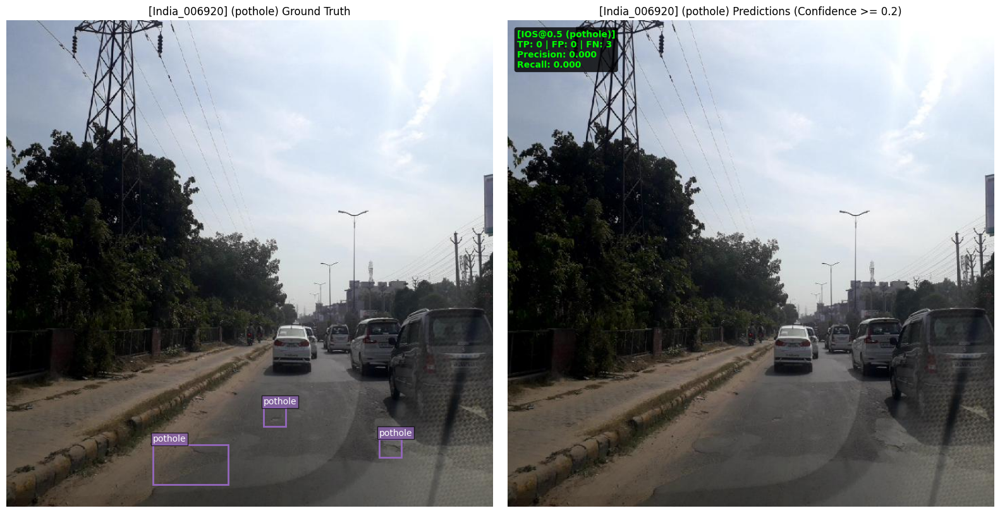

In [25]:
pothole_low_recall = dataset_evaluator.filter(
    class_names="pothole",
    model_confidence_threshold=0.2,
    metric="recall",
    eq="<",
    class_confidence_threshold=0.5,
)

pothole_low_recall.plot(
    num_samples=10,
    confidence_threshold=0.2,
    class_names="pothole",
    show_stats = True
)


Filter matched 1190 / 5758 images.

--- Metrics for image: [Japan_007722]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    8 |       5 |    4 |    1 |    4 |         0.8 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


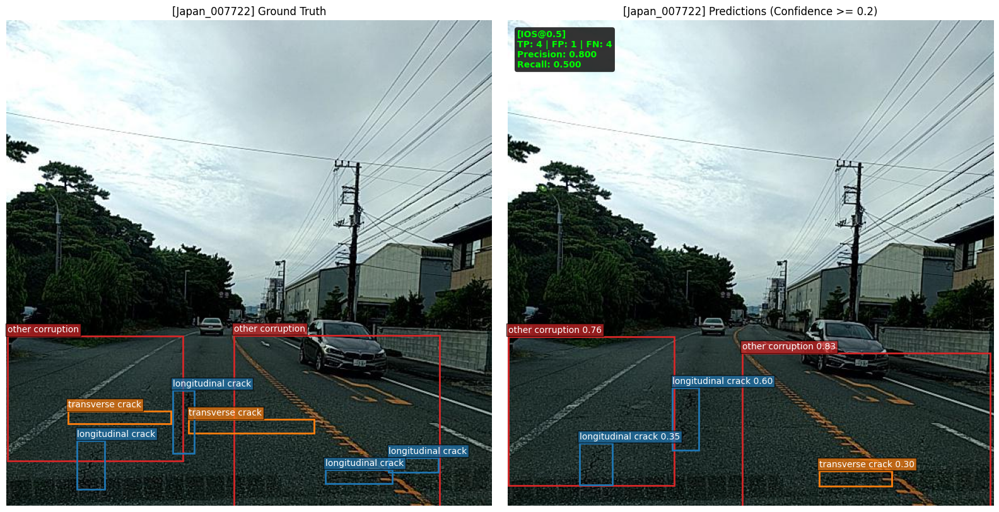


--- Metrics for image: [United_States_000502]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       4 |    2 |    2 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


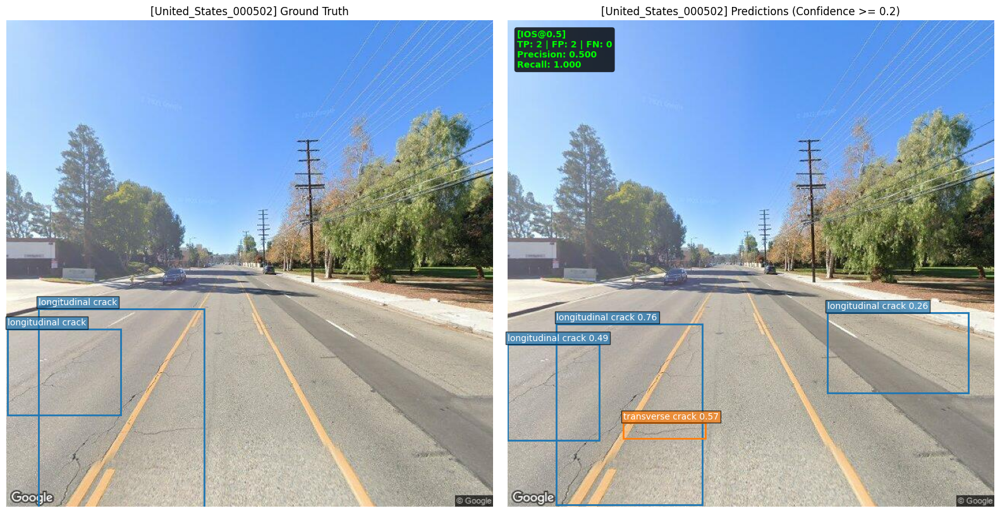


--- Metrics for image: [India_006656]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       2 |    1 |    1 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


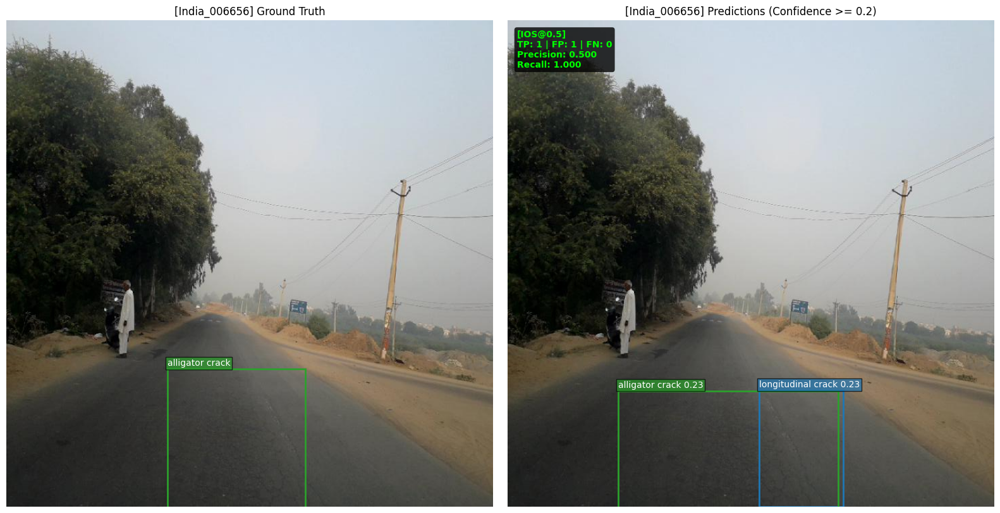


--- Metrics for image: [India_003517]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       1 |    0 |    1 |    2 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


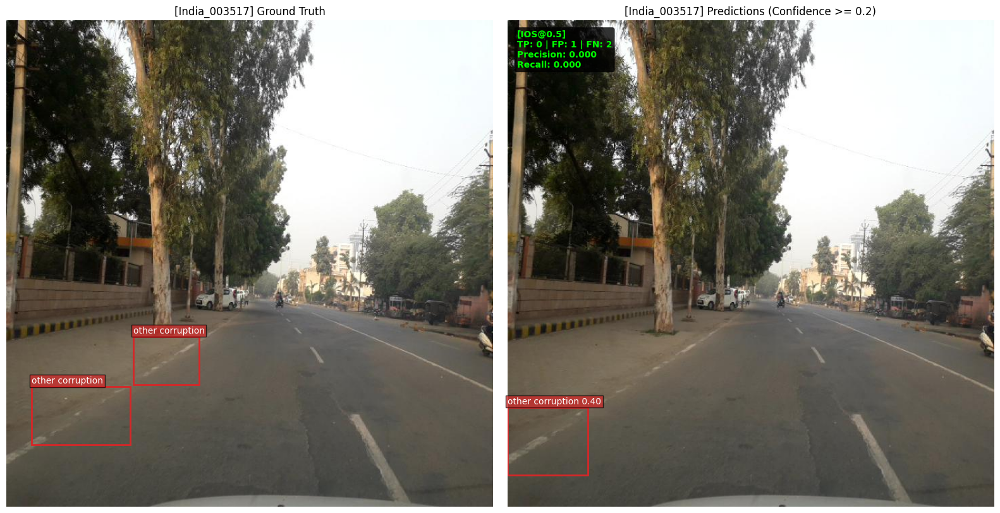


--- Metrics for image: [Czech_000608]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


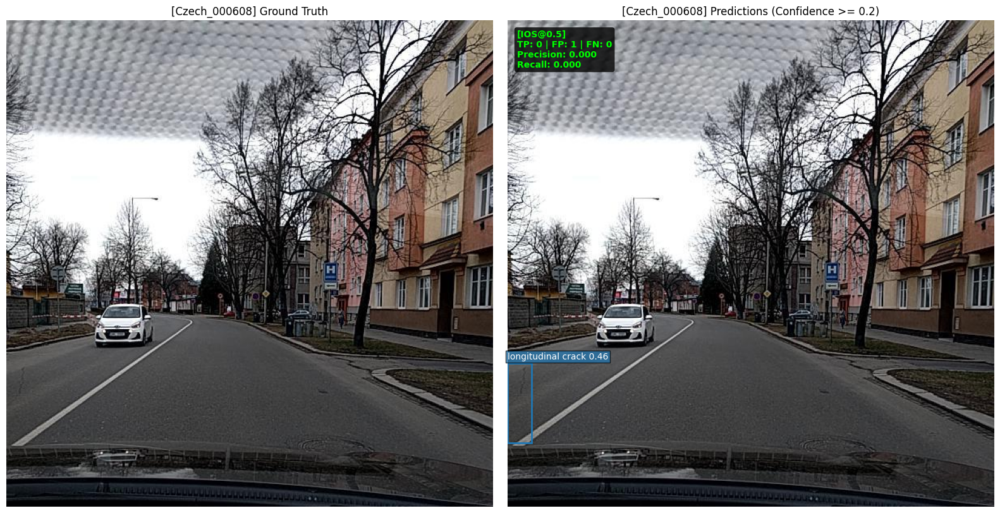


--- Metrics for image: [Czech_000570]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


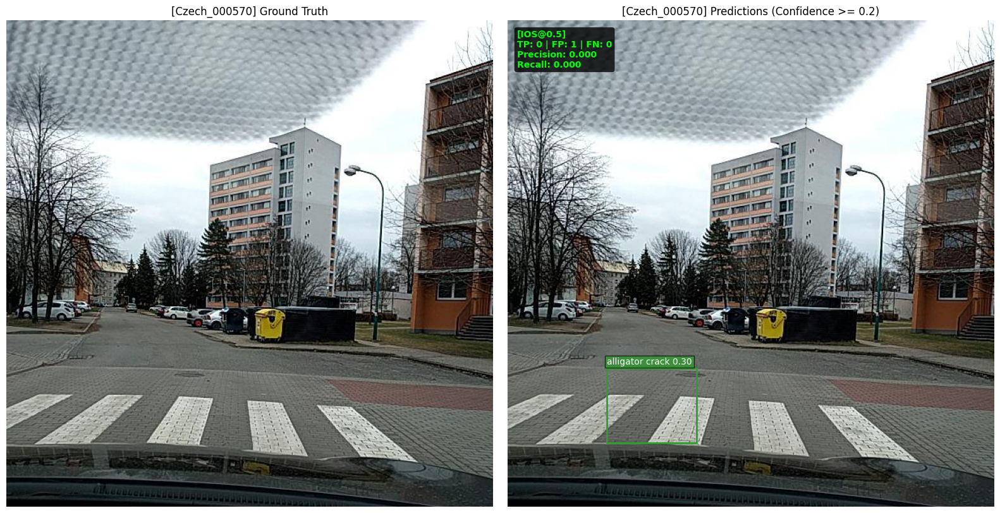


--- Metrics for image: [China_MotorBike_001095]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    2 |       4 |    2 |    2 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


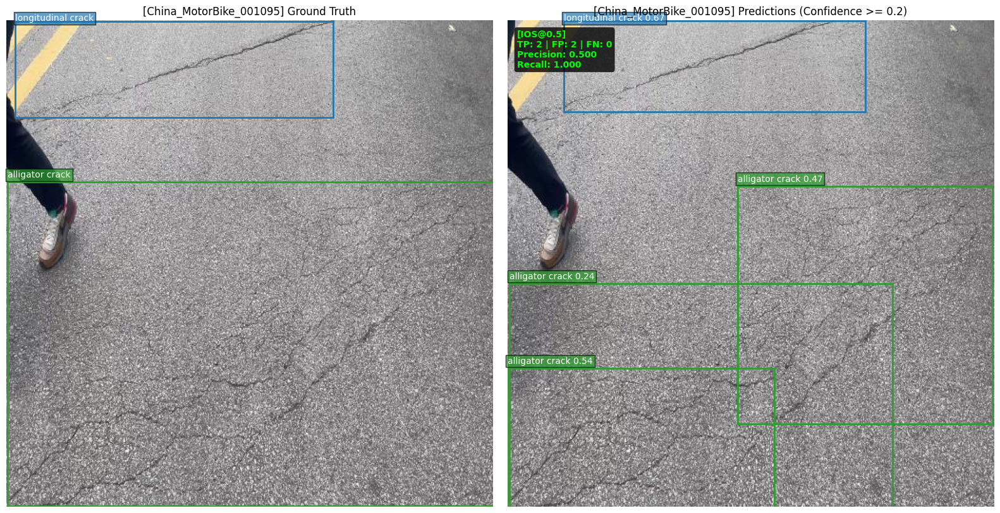


--- Metrics for image: [Norway_004467]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    5 |       4 |    1 |    3 |    4 |        0.25 |      0.2 |
+------------------+------+---------+------+------+------+-------------+----------+


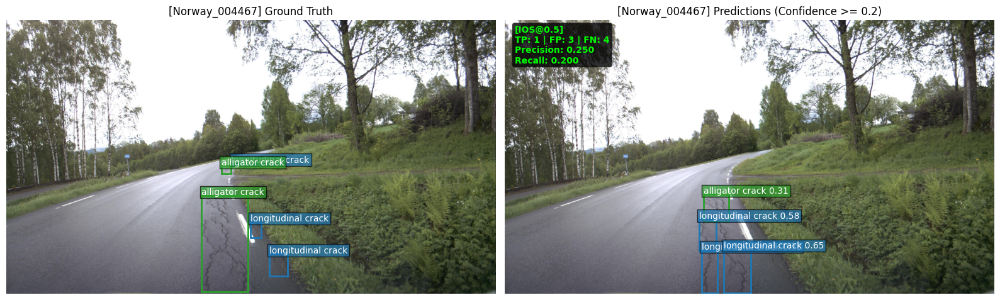


--- Metrics for image: [Japan_010775]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    5 |       6 |    4 |    2 |    1 |      0.6667 |      0.8 |
+------------------+------+---------+------+------+------+-------------+----------+


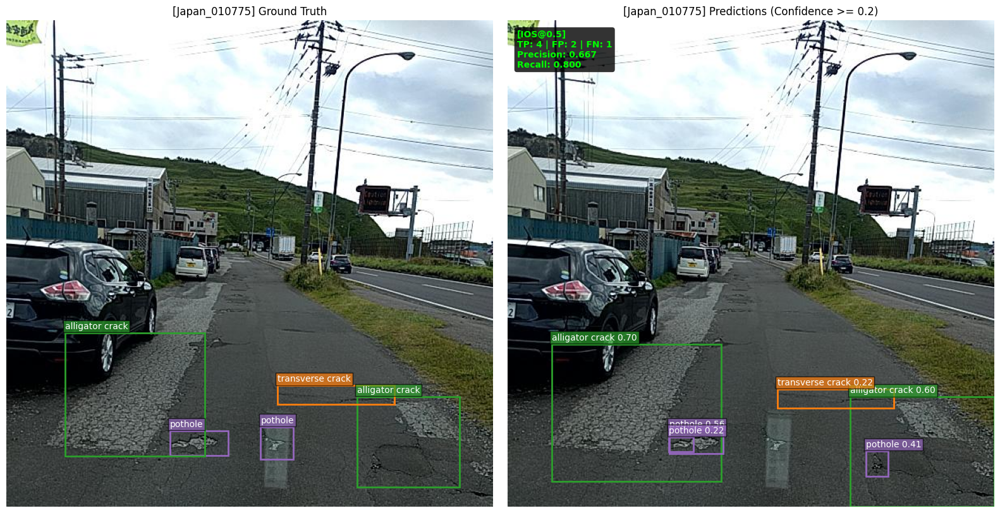


--- Metrics for image: [Czech_000469]  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


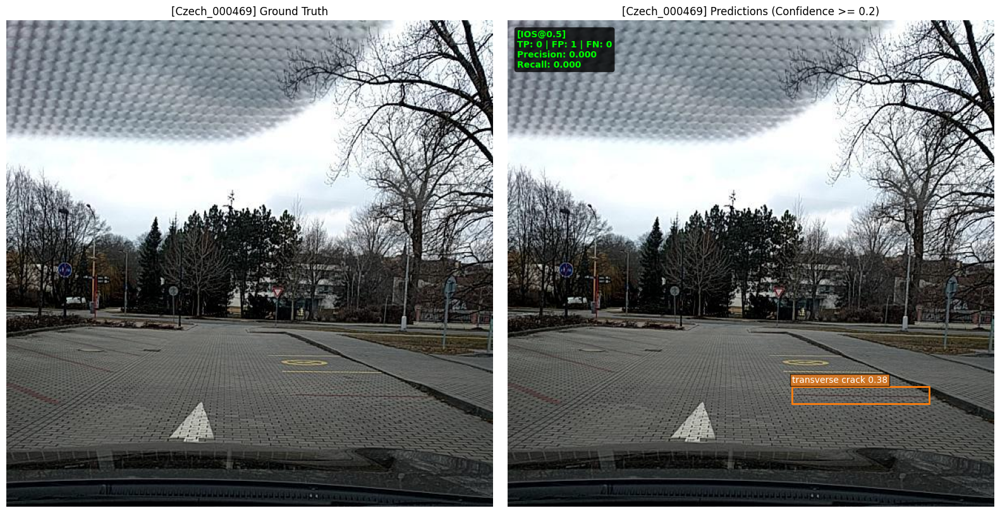

In [26]:
low_precision_images = dataset_evaluator.filter(
    class_names=[
        "longitudinal crack",
        "transverse crack",
        "alligator crack",
        "other corruption",
        "pothole",
    ],
    model_confidence_threshold=0.2,
    metric="precision",
    eq="<",
    class_confidence_threshold=0.5,
)

low_precision_images.plot(
    num_samples=10,
    confidence_threshold=0.2,
    show_stats=True
)

In [27]:
poor_localization = dataset_evaluator.filter(
    class_names=[
        "longitudinal crack",
        "transverse crack",
        "alligator crack",
        "other corruption",
        "pothole",
    ],
    model_confidence_threshold=0.2,
    metric="mean_iou",
    eq="<",
    class_confidence_threshold=0.9,
)

poor_localization.plot(
    num_samples=5,
    confidence_threshold=0.2,
)

Filter matched 0 / 5758 images.


Evaluating (IOS): 0img [00:00, ?img/s]

No image objects available to plot.


Filter matched 177 / 5758 images.
Number of images with >= 2 FP potholes: 177

--- Metrics for image: [China_Drone_001118] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


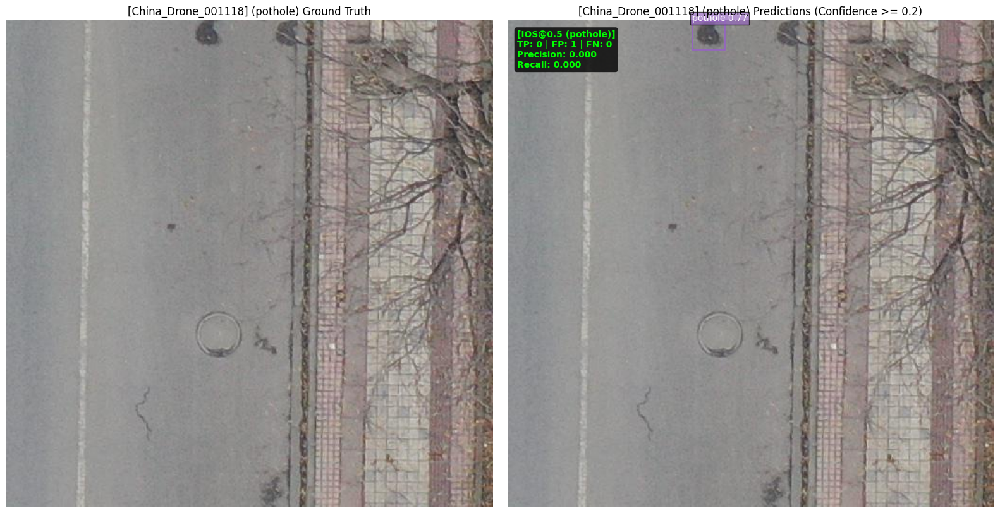


--- Metrics for image: [China_Drone_001270] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


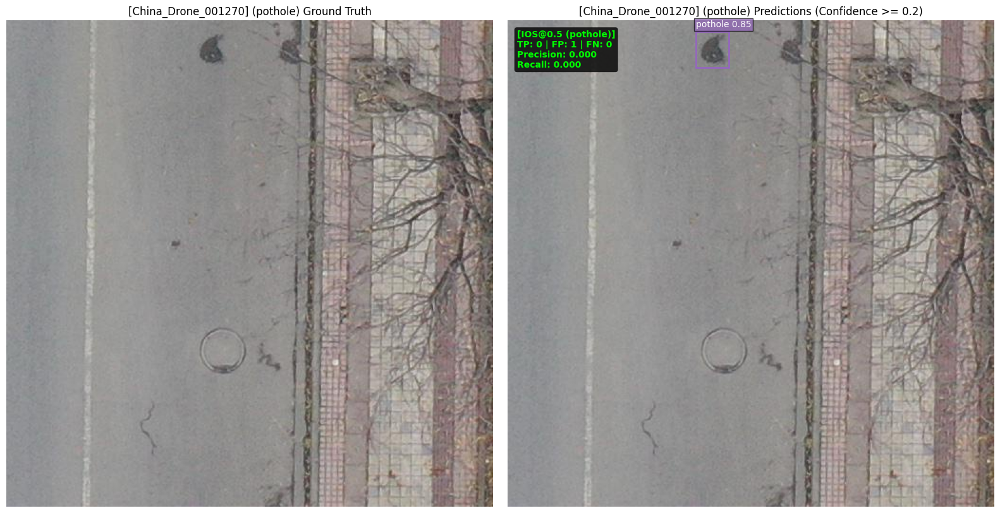


--- Metrics for image: [China_Drone_001555] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       2 |    1 |    1 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


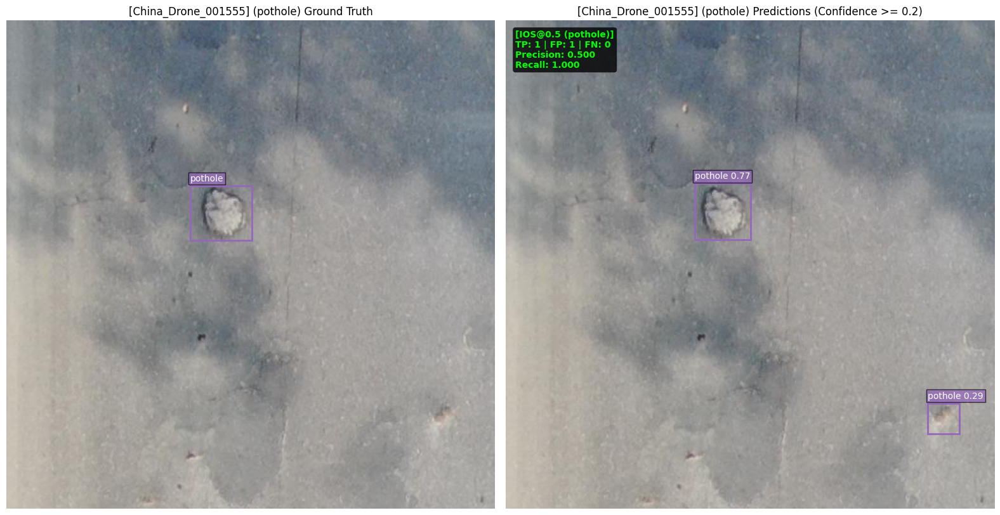


--- Metrics for image: [China_Drone_002276] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


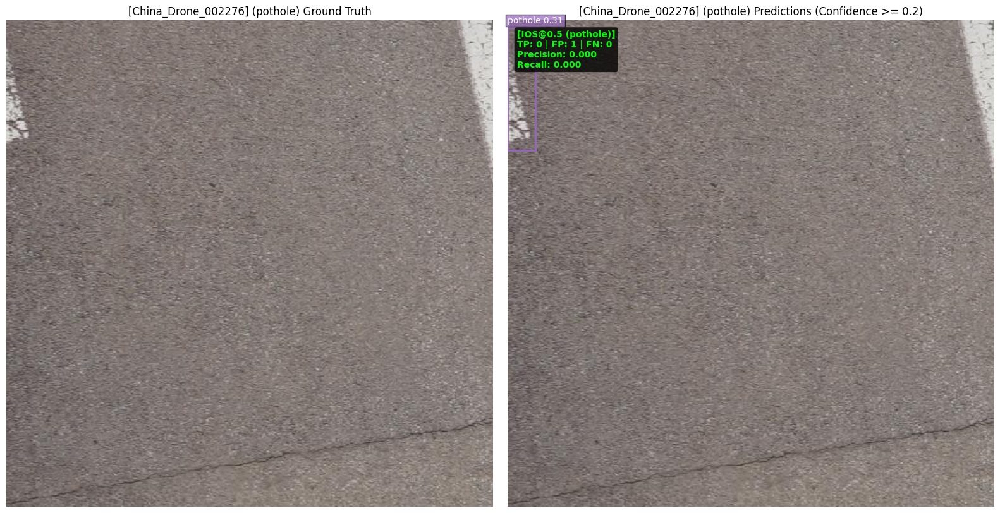


--- Metrics for image: [China_MotorBike_000558] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


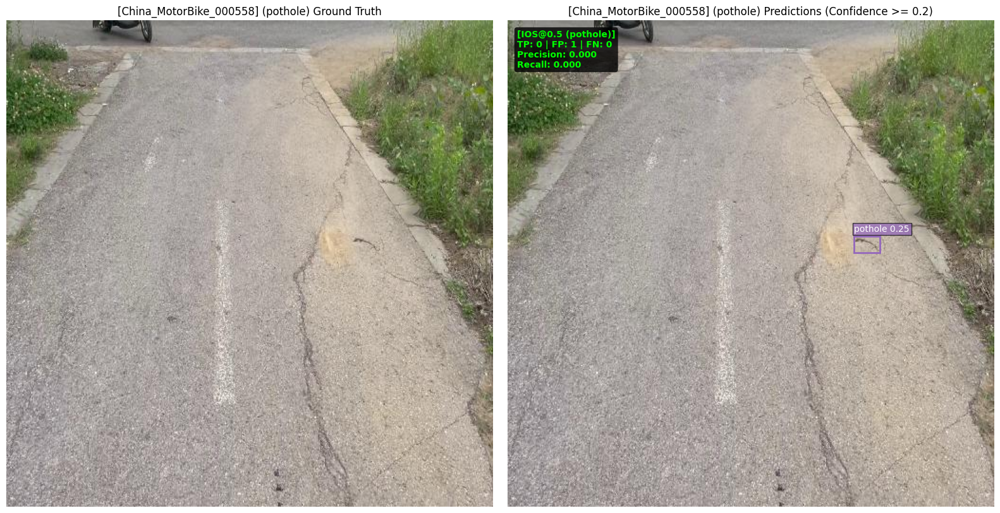


--- Metrics for image: [China_MotorBike_000996] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       2 |    1 |    1 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


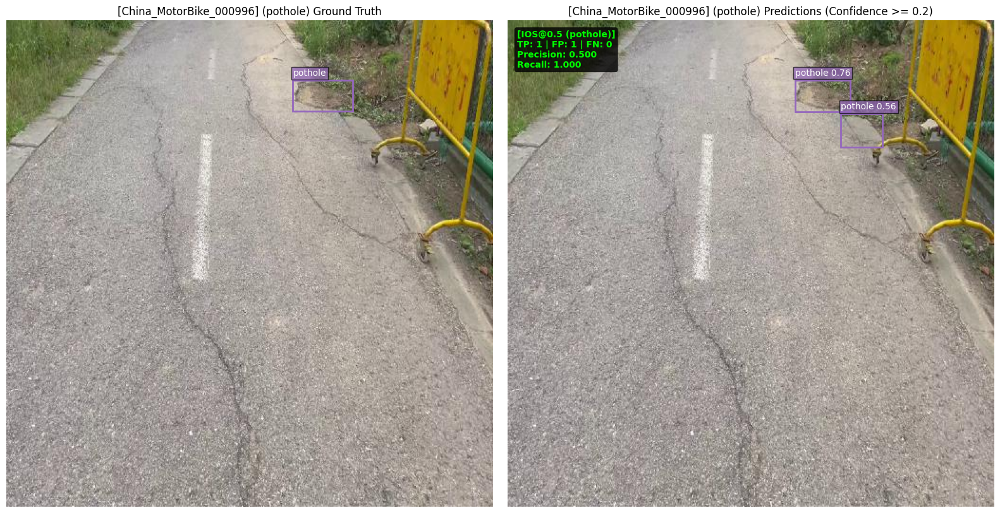


--- Metrics for image: [China_MotorBike_001553] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       2 |    1 |    1 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


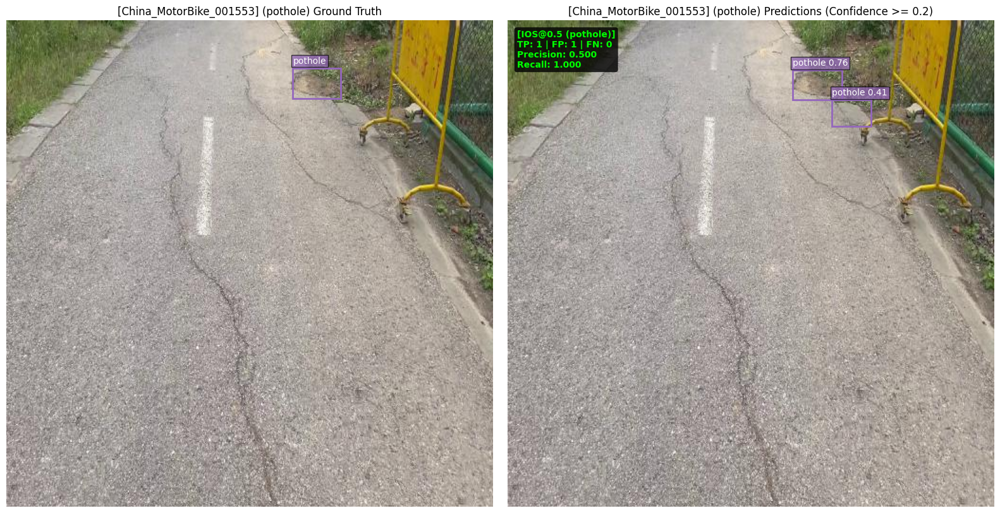


--- Metrics for image: [Czech_000127] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


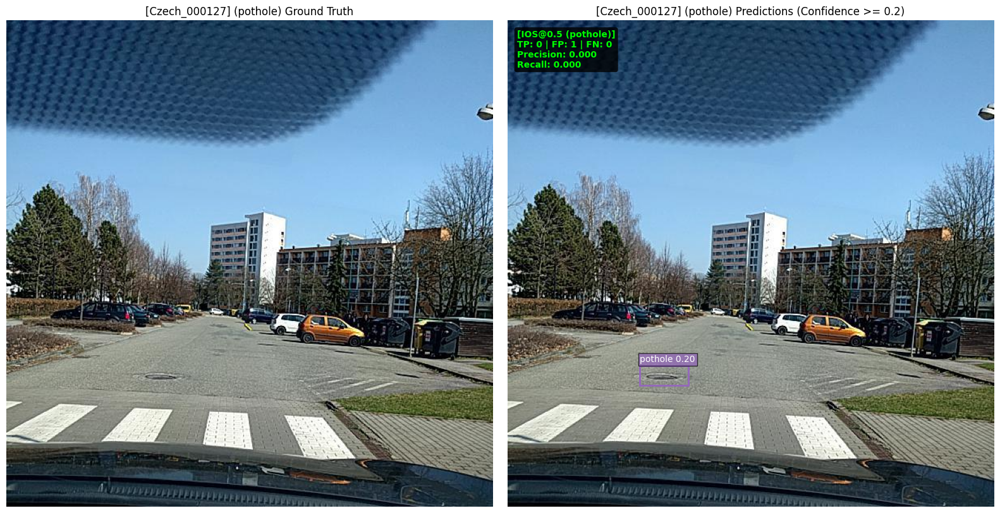


--- Metrics for image: [Czech_000281] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


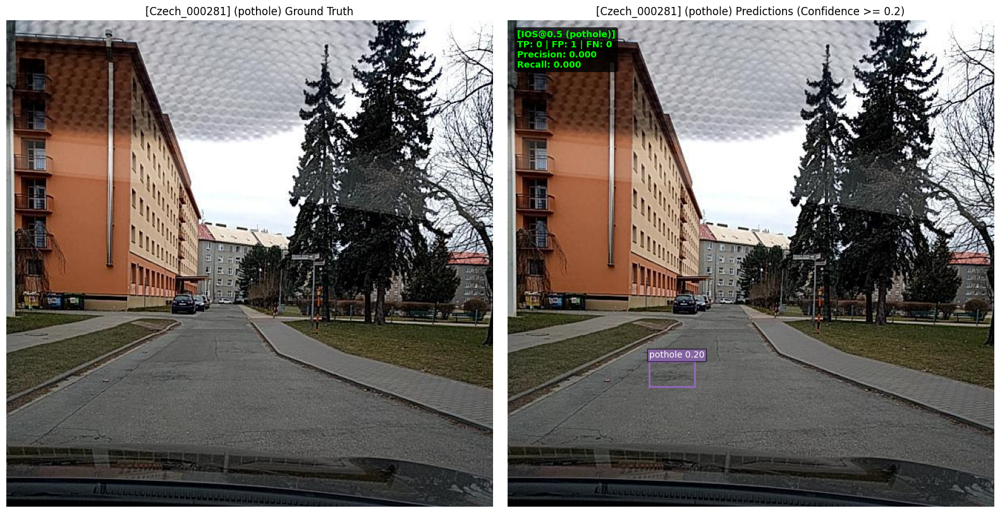


--- Metrics for image: [Czech_000786] (pothole)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


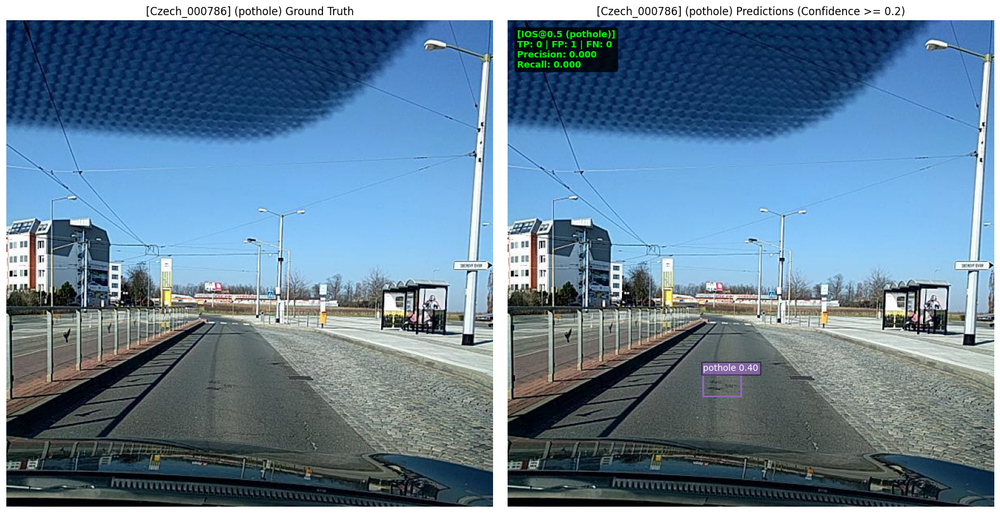

In [28]:
pothole_fp = dataset_evaluator.filter(
    class_names="pothole",
    model_confidence_threshold=0.2,
    metric="fp",
    eq=">=",
    class_confidence_threshold=1,
)
print(f"Number of images with >= 2 FP potholes: {len(pothole_fp.all_image_object)}")
pothole_fp.plot(
    num_samples=10,
    confidence_threshold=0.2,
    class_names="pothole",
    random_sample=False,
    show_stats=True
)


Filter matched 843 / 5758 images.
Images with >= 2 ghost cracks: 843

--- Metrics for image: [India_005686] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


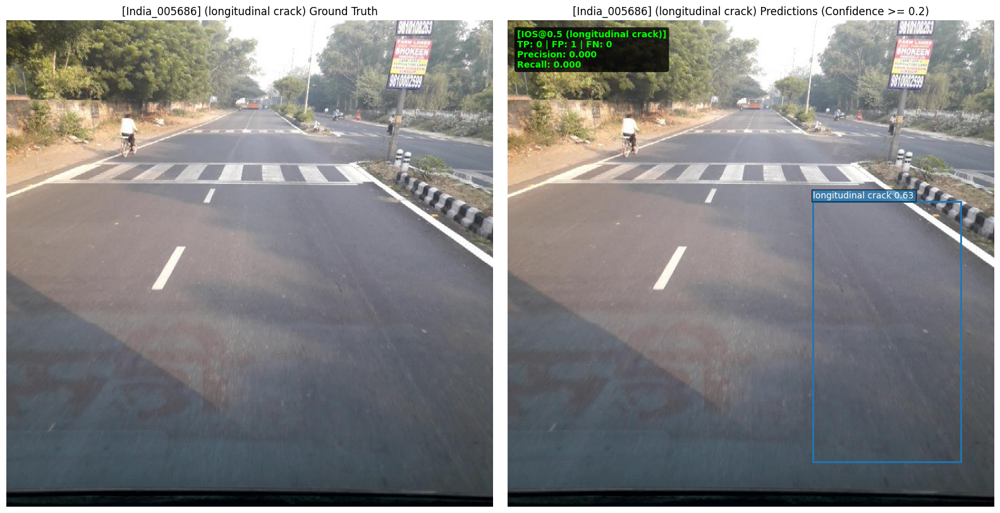


--- Metrics for image: [Norway_003209] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    3 |       4 |    3 |    1 |    0 |        0.75 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


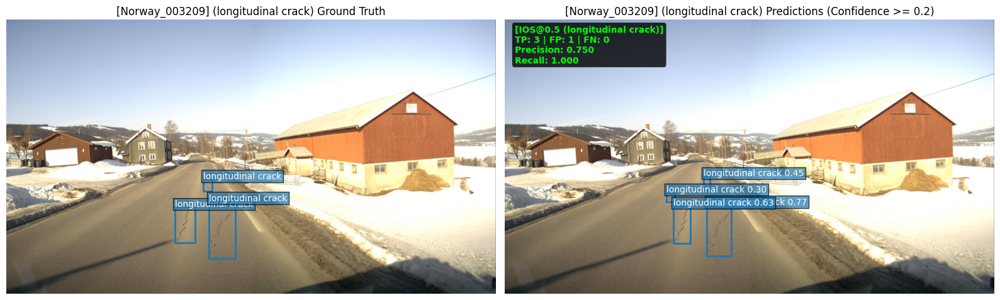


--- Metrics for image: [United_States_000415] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    1 |       3 |    1 |    2 |    0 |      0.3333 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


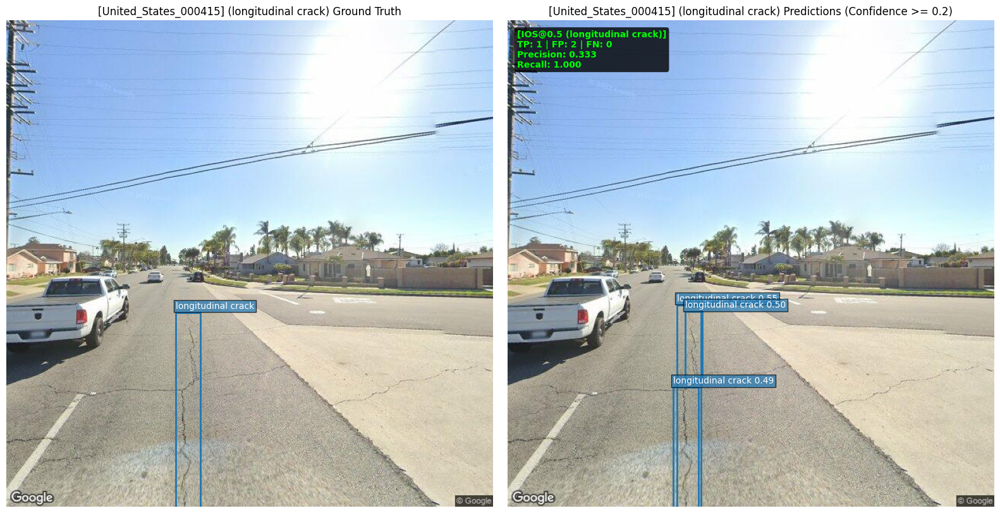


--- Metrics for image: [United_States_001065] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


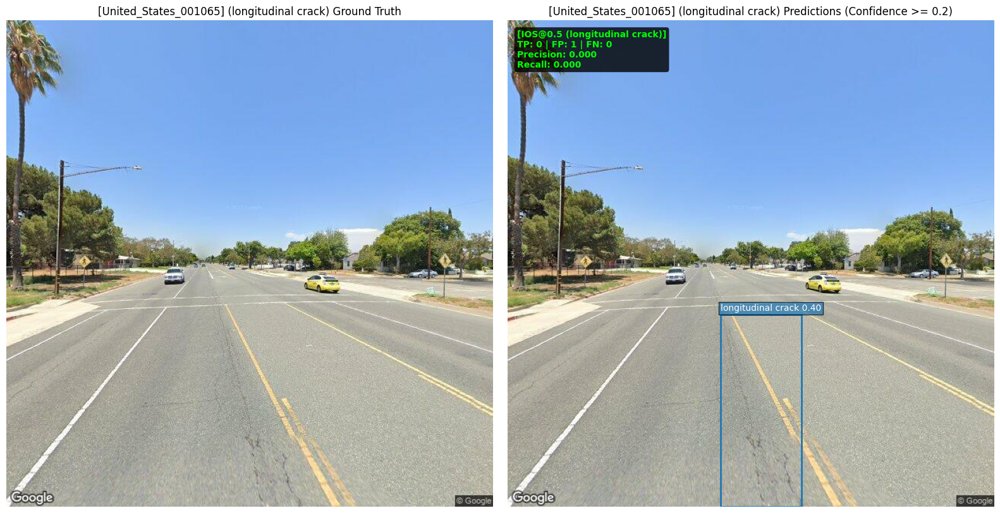


--- Metrics for image: [Japan_012985] (longitudinal crack)  (Conf: 0.2, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.2 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


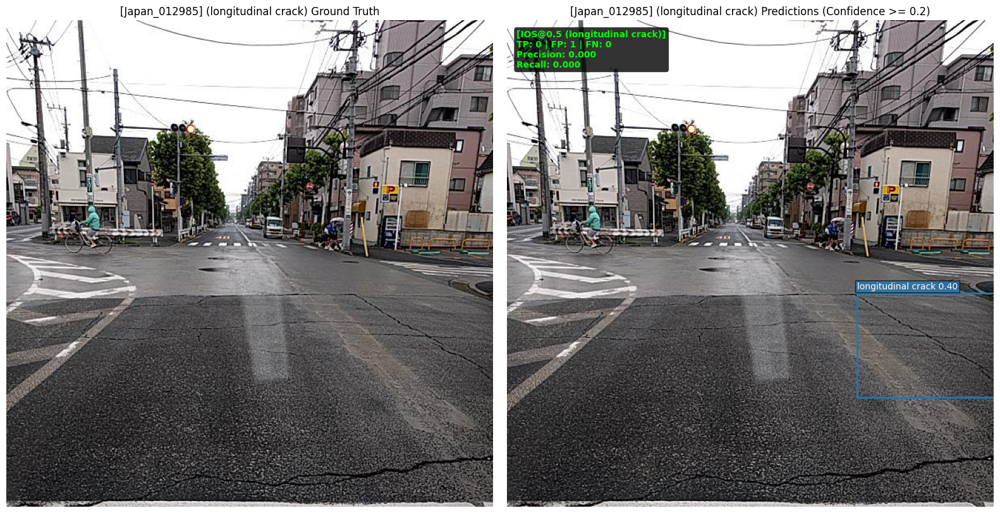

In [29]:
# Find images with 2 or more false positive longitudinal cracks
ghost_cracks = dataset_evaluator.filter(
    class_names="longitudinal crack",
    model_confidence_threshold=0.2,
    metric="fp",
    eq=">=",
    class_confidence_threshold=1
)

print(f"Images with >= 2 ghost cracks: {len(ghost_cracks.all_image_object)}")

# Plot 3 samples to see what road feature fooled the model
ghost_cracks.plot(
    num_samples=5,
    confidence_threshold=0.2,
    class_names="longitudinal crack",
    show_stats=True
)